In [1]:
import sys
from pathlib import Path

ROOT_DIR = Path.cwd().parent
sys.path.insert(0, str(ROOT_DIR / "src"))

In [2]:
import os
import torch
from torch.utils.data import DataLoader

from model import YOLOv1
from dataset import VOCDataset
from loss import YOLOv1Loss

In [3]:
# Configuration
EPOCHS = 20
BATCH_SIZE = 24
LEARNING_RATE = 1e-4

voc2007_dir = ROOT_DIR / "data" / "VOCdevkit" / "VOC2007"
voc2012_dir = ROOT_DIR / "data" / "VOCdevkit" / "VOC2012"

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


In [4]:
# Training: VOC 2007 + VOC 2012 train splits
train_dataset = VOCDataset(
    [voc2007_dir, voc2012_dir],
    split="train",
)
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
)

# Validation: VOC 2012 val split only
val_dataset = VOCDataset(
    [voc2012_dir],
    split="val",
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

In [5]:
# Model, loss, optimizer
net = YOLOv1().to(device)
criterion = YOLOv1Loss()

optimizer = torch.optim.SGD(
    net.parameters(),
    lr=LEARNING_RATE,
    momentum=0.9,
    weight_decay=5e-4,
)

# Checkpoint configuration
checkpoint_dir = ROOT_DIR / "checkpoints"
checkpoint_dir.mkdir(parents=True, exist_ok=True)

best_val_loss = float("inf")
checkpoint_path = checkpoint_dir / "yolov1_best.pth"

In [ ]:
train_losses = []
val_losses = []

In [ ]:
# Training and validation

best_val_loss = float("inf")

for epoch in range(EPOCHS):
    # Training
    net.train()
    train_total_loss = 0.0

    for X, y in train_loader:
        X = X.to(device)
        y = y.to(device)

        optimizer.zero_grad()

        y_pred = net(X)
        loss = criterion(y_pred, y)

        loss.backward()
        optimizer.step()

        train_total_loss += loss.item()

    avg_train_loss = train_total_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    # Validation
    net.eval()
    val_total_loss = 0.0

    with torch.no_grad():
        for X, y in val_loader:
            X = X.to(device)
            y = y.to(device)

            y_pred = net(X)
            loss = criterion(y_pred, y)

            val_total_loss += loss.item()

    avg_val_loss = val_total_loss / len(val_loader)
    val_losses.append(avg_val_loss)

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] "
        f"| Train Loss: {avg_train_loss:.4f} "
        f"| Val Loss: {avg_val_loss:.4f}"
    )

    # Save only when validation loss improves
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss

        torch.save(
            net.state_dict(),
            checkpoint_path,
        )

print(f"Training complete. Best Val Loss: {best_val_loss:.4f}")
print(f"Best model saved at: {checkpoint_path}")

In [7]:
# Load recorded losses when training was performed in a separate session.
# Keep existing losses if both lists are already populated.

if not train_losses and not val_losses:
    train_losses = [
        145.02012616482838, 129.46772045435782, 127.69156393156803,
        126.09990049312135, 125.62451479942389, 125.47691735581823,
        125.33229496458182, 123.45209309658573, 122.50858945262675,
        122.48342599674147, 122.4888966285105, 122.32422130796027,
        122.35827211874914, 122.29542332418458, 122.23682997456098,
        122.2454812186105, 122.1520340588628, 122.10940352681774,
        122.05432299066216, 122.06615234463972,
    ]

    val_losses = [
        123.94267558659055, 120.70522006941431, 119.7540131557135,
        118.74877314312468, 118.96790973051095, 118.83584990324798,
        118.73314955597552, 116.4630488015006, 116.03067091953608,
        116.53646596272786, 116.26638326134702, 116.09031074429735,
        116.25410175715945, 116.19017204630032, 116.17712289315683,
        116.0977396081995, 116.25868598718212, 116.11134124881445,
        116.19235857425893, 116.234231328768,
    ]

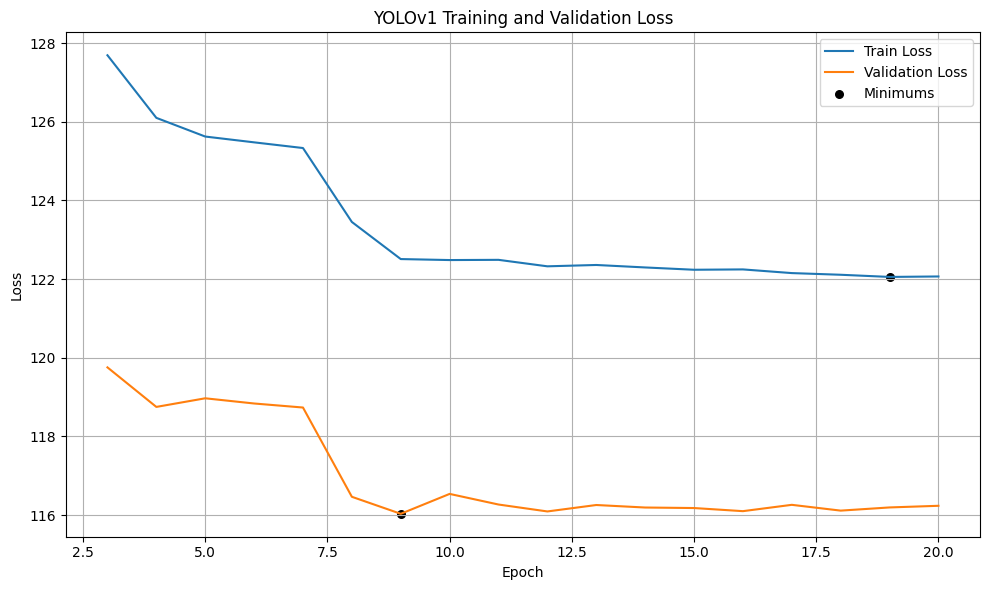

In [18]:
import matplotlib.pyplot as plt

epochs = range(3, len(train_losses) + 1)

plt.figure(figsize=(10, 6))
plt.plot(epochs, train_losses[2:], label="Train Loss")
plt.plot(epochs, val_losses[2:], label="Validation Loss")

train_min_idx = min(range(2, len(train_losses)), key=lambda i: train_losses[i])
val_min_idx = min(range(2, len(val_losses)), key=lambda i: val_losses[i])

plt.scatter(train_min_idx + 1, train_losses[train_min_idx],
            marker="o", s=30, color="black", label="Minimums")
plt.scatter(val_min_idx + 1, val_losses[val_min_idx],
            marker="o", s=30, color="black", label="_nolegend_")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("YOLOv1 Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()